In [103]:
import pandas as pd
import trxtools.methods as ttm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from trxtools.utils.names import cleanNames

## Unique reads

In [104]:
df00_uniq = pd.read_csv('../03a_FeatureCounts_umitools/featureCounts_umitools_uniq_TPM.txt', sep='\t', index_col=0)
df00_uniq = cleanNames(df00_uniq, ['02c_alignment_all_umitools/SB060916_', '_all_dedup.bam'])
df00_uniq = df00_uniq[[
    'Mtr4_wt_0min_1', 'Mtr4_wt_0min_2', 'Mtr4_wt_0min_mock_1', 'Mtr4_wt_4min_1', 'Mtr4_wt_4min_2', 'Mtr4_wt_8min_1', 'Mtr4_wt_8min_2',
    'Nab3_wt_0min_1', 'Nab3_wt_0min_2', 'Nab3_wt_4min_1', 'Nab3_wt_8min_1', 'Nab3_wt_8min_2',
    'Rpo21_wt_0min_1', 'Rpo21_wt_0min_2', 'Rpo21_wt_0min_mock_1', 'Rpo21_wt_4min_1', 'Rpo21_wt_4min_2', 'Rpo21_wt_8min_1', 'Rpo21_wt_8min_2'
]]


In [ ]:
gtf_path = "../references/Saccharomyces_cerevisiae.EF4.74_SGDv64_CUTandSUT_withUTRs_noEstimates_antisense_intergenic_4xlncRNAs_final.pyCheckGTFfile.output.corrected.gtf"
gtf = pd.read_csv(gtf_path, sep='\t', comment='#', header=None)
gtf_gene_df = pd.DataFrame({
    'gene_id': gtf[8].str.extract(r'gene_id "([^"]+)"', expand=False),
    'biotype': gtf[1],
    'gene_name': gtf[8].str.extract(r'gene_name "([^"]+)"', expand=False)
})

gtf_gene_df.head()

,0,1,2,3,4,5,6,7,8
0,chrIV,protein_coding,CDS,1802,2950,.,+,0,"gene_id ""YDL248W""; transcript_id ""YDL248W""; ex..."
1,chrIV,protein_coding,start_codon,1802,1804,.,+,0,"gene_id ""YDL248W""; transcript_id ""YDL248W""; ex..."
2,chrIV,protein_coding,stop_codon,2951,2953,.,+,0,"gene_id ""YDL248W""; transcript_id ""YDL248W""; ex..."
3,chrIV,protein_coding,CDS,3762,3833,.,+,0,"gene_id ""YDL247W-A""; transcript_id ""YDL247W-A""..."
4,chrIV,protein_coding,start_codon,3762,3764,.,+,0,"gene_id ""YDL247W-A""; transcript_id ""YDL247W-A""..."


In [107]:
mrna_genes = gtf_gene_df.loc[gtf_gene_df['biotype'] == 'protein_coding', :].drop_duplicates(subset='gene_id')
mrna_genes.head()

,gene_id,biotype,gene_name
0,YDL248W,protein_coding,COS7
3,YDL247W-A,protein_coding,YDL247W-A
6,YDL247W,protein_coding,MPH2
9,YDL246C,protein_coding,SOR2
12,YDL245C,protein_coding,HXT15


In [ ]:
# From Supp. Table S1
top_mrna_list = pd.read_csv('references/top_2k_mRNAs.csv', header=None, names=['gene_name'])
top_mrna_list

,gene_name
0,BTN2
1,HSP42
2,SPI1
3,HSP30
4,HSP104
...,...
1995,GCD1
1996,SFG1
1997,NOP58
1998,UTP8


In [109]:
top_2k_mrna = mrna_genes.loc[mrna_genes['gene_name'].isin(top_mrna_list['gene_name']), :].drop_duplicates(subset='gene_id')
top_2k_mrna

,gene_id,biotype,gene_name
30,YDL240W,protein_coding,LRG1
48,YDL234C,protein_coding,GYP7
57,YDL231C,protein_coding,BRE4
63,YDL229W,protein_coding,SSB1
69,YDL227C,protein_coding,HO
...,...,...,...
20246,YAR015W,protein_coding,ADE1
20288,YAR042W,protein_coding,SWH1
20340,Q0065,protein_coding,AI4
20346,Q0045,protein_coding,COX1


Fig 1B

<Axes: >

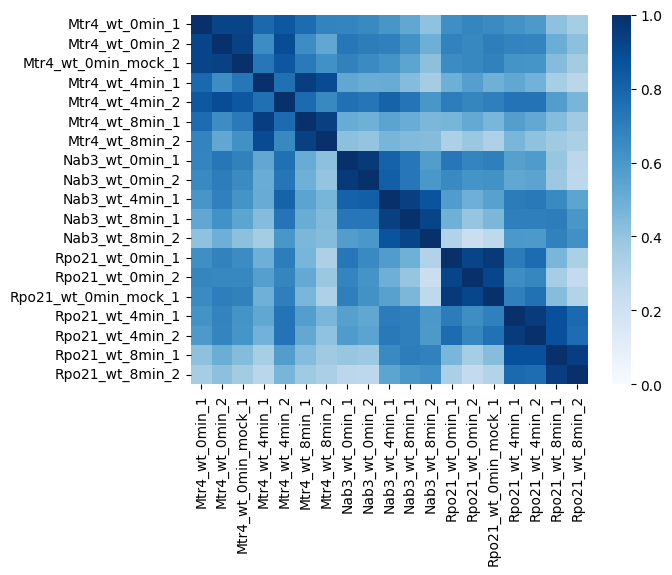

In [110]:
plotdata = df00_uniq.loc[df00_uniq.index.isin(top_2k_mrna['gene_id']), :]
sns.heatmap(
    plotdata.corr('pearson'),
    vmin=0, vmax=1,
    cmap='Blues',
)

Fig 1DE

In [111]:
cut_genes = gtf_gene_df.loc[gtf_gene_df['biotype'] == 'CUTs', :].drop_duplicates(subset='gene_id')
sut_genes = gtf_gene_df.loc[gtf_gene_df['biotype'] == 'SUTs', :].drop_duplicates(subset='gene_id')

In [112]:
# Exclude mock samples
sample_cols = df00_uniq.columns[
    ~df00_uniq.columns.str.contains(r"(^|_)mock(_|$)", case=False, regex=True)
]

# Remove replicate suffix and average replicates
sample_groups = sample_cols.to_series().str.replace(
    r"_\d+$", "", regex=True
)

df00_mean = (
    df00_uniq.loc[:, sample_cols]
    .T.groupby(sample_groups, sort=False)
    .mean()
    .T
)

/tmp/ipykernel_770968/847770206.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ~df00_uniq.columns.str.contains(r"(^|_)mock(_|$)", case=False, regex=True)


In [113]:
df00_mean_cuts = df00_mean.loc[df00_mean.index.isin(cut_genes['gene_id']), :].copy().add(0.1)
df00_mean_suts = df00_mean.loc[df00_mean.index.isin(sut_genes['gene_id']), :].copy().add(0.1)
df00_mean_mrnas = df00_mean.loc[df00_mean.index.isin(mrna_genes['gene_id']), :].copy().add(0.1)

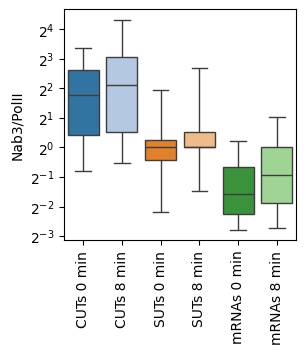

In [114]:
#Nab3/PolII
plotdata = pd.DataFrame({
    'CUTs 0 min': df00_mean_cuts['Nab3_wt_0min'].div(df00_mean_cuts['Rpo21_wt_0min']),
    'CUTs 8 min': df00_mean_cuts['Nab3_wt_8min'].div(df00_mean_cuts['Rpo21_wt_8min']),
    'SUTs 0 min': df00_mean_suts['Nab3_wt_0min'].div(df00_mean_suts['Rpo21_wt_0min']),
    'SUTs 8 min': df00_mean_suts['Nab3_wt_8min'].div(df00_mean_suts['Rpo21_wt_8min']),
    'mRNAs 0 min': df00_mean_mrnas['Nab3_wt_0min'].div(df00_mean_mrnas['Rpo21_wt_0min']),
    'mRNAs 8 min': df00_mean_mrnas['Nab3_wt_8min'].div(df00_mean_mrnas['Rpo21_wt_8min']),
})
fig, ax = plt.subplots(figsize=(3, 3))
sns.boxplot(
    data=plotdata,
    showfliers=False, whis=(10,90),
    palette='tab20',
    ax=ax
)
ax.set_yscale('log', base=2)
ax.set_ylabel('Nab3/PolII')
ax.tick_params(axis='x', labelrotation=90)

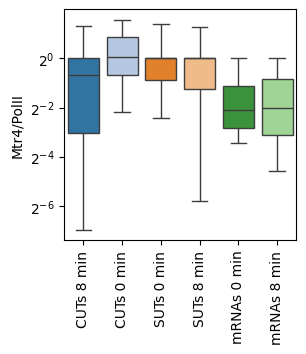

In [115]:
#Mtr4/PolII
plotdata = pd.DataFrame({
    'CUTs 8 min': df00_mean_cuts['Mtr4_wt_8min'].div(df00_mean_cuts['Rpo21_wt_8min']),
    'CUTs 0 min': df00_mean_cuts['Mtr4_wt_0min'].div(df00_mean_cuts['Rpo21_wt_0min']),
    'SUTs 0 min': df00_mean_suts['Mtr4_wt_0min'].div(df00_mean_suts['Rpo21_wt_0min']),
    'SUTs 8 min': df00_mean_suts['Mtr4_wt_8min'].div(df00_mean_suts['Rpo21_wt_8min']),
    'mRNAs 0 min': df00_mean_mrnas['Mtr4_wt_0min'].div(df00_mean_mrnas['Rpo21_wt_0min']),
    'mRNAs 8 min': df00_mean_mrnas['Mtr4_wt_8min'].div(df00_mean_mrnas['Rpo21_wt_8min']),
})
fig, ax = plt.subplots(figsize=(3, 3))
sns.boxplot(
    data=plotdata,
    showfliers=False, whis=(10,90),
    palette='tab20',
    ax=ax
)
ax.set_yscale('log', base=2)
ax.set_ylabel('Mtr4/PolII')
ax.tick_params(axis='x', labelrotation=90)

## Multimapping reads

In [116]:
df01_multi = pd.read_csv('../03a_FeatureCounts_umitools/featureCounts_umitools_multimappers_TPM.txt', sep='\t', index_col=0)
df01_multi = cleanNames(df01_multi, ['02c_alignment_all_umitools/SB060916_', '_all_dedup.bam'])
df01_multi = df01_multi[[
    'Mtr4_wt_0min_1', 'Mtr4_wt_0min_2', 'Mtr4_wt_0min_mock_1', 'Mtr4_wt_4min_1', 'Mtr4_wt_4min_2', 'Mtr4_wt_8min_1', 'Mtr4_wt_8min_2',
    'Nab3_wt_0min_1', 'Nab3_wt_0min_2', 'Nab3_wt_4min_1', 'Nab3_wt_8min_1', 'Nab3_wt_8min_2',
    'Rpo21_wt_0min_1', 'Rpo21_wt_0min_2', 'Rpo21_wt_0min_mock_1', 'Rpo21_wt_4min_1', 'Rpo21_wt_4min_2', 'Rpo21_wt_8min_1', 'Rpo21_wt_8min_2'
]]

In [117]:
gtf_path = "../references/Saccharomyces_cerevisiae.EF4.74_SGDv64_CUTandSUT_withUTRs_noEstimates_antisense_intergenic_4xlncRNAs_final.pyCheckGTFfile.output.corrected.gtf"
gtf = pd.read_csv(gtf_path, sep='\t', comment='#', header=None)
gtf.head()

,0,1,2,3,4,5,6,7,8
0,chrIV,protein_coding,CDS,1802,2950,.,+,0,"gene_id ""YDL248W""; transcript_id ""YDL248W""; ex..."
1,chrIV,protein_coding,start_codon,1802,1804,.,+,0,"gene_id ""YDL248W""; transcript_id ""YDL248W""; ex..."
2,chrIV,protein_coding,stop_codon,2951,2953,.,+,0,"gene_id ""YDL248W""; transcript_id ""YDL248W""; ex..."
3,chrIV,protein_coding,CDS,3762,3833,.,+,0,"gene_id ""YDL247W-A""; transcript_id ""YDL247W-A""..."
4,chrIV,protein_coding,start_codon,3762,3764,.,+,0,"gene_id ""YDL247W-A""; transcript_id ""YDL247W-A""..."


In [118]:
gtf_gene_df = pd.DataFrame({
    'gene_id': gtf[8].str.extract(r'gene_id "([^"]+)"', expand=False),
    'biotype': gtf[1],
    'gene_name': gtf[8].str.extract(r'gene_name "([^"]+)"', expand=False)
})

gtf_gene_df.head()

,gene_id,biotype,gene_name
0,YDL248W,protein_coding,COS7
1,YDL248W,protein_coding,COS7
2,YDL248W,protein_coding,COS7
3,YDL247W-A,protein_coding,YDL247W-A
4,YDL247W-A,protein_coding,YDL247W-A


In [119]:
mrna_genes = gtf_gene_df.loc[gtf_gene_df['biotype'] == 'protein_coding', :].drop_duplicates(subset='gene_id')
mrna_genes.head()

,gene_id,biotype,gene_name
0,YDL248W,protein_coding,COS7
3,YDL247W-A,protein_coding,YDL247W-A
6,YDL247W,protein_coding,MPH2
9,YDL246C,protein_coding,SOR2
12,YDL245C,protein_coding,HXT15


In [120]:
top_mrna_list = pd.read_csv('references/top_2k_mRNAs.csv', header=None, names=['gene_name'])
top_mrna_list

,gene_name
0,BTN2
1,HSP42
2,SPI1
3,HSP30
4,HSP104
...,...
1995,GCD1
1996,SFG1
1997,NOP58
1998,UTP8


In [121]:
top_2k_mrna = mrna_genes.loc[mrna_genes['gene_name'].isin(top_mrna_list['gene_name']), :].drop_duplicates(subset='gene_id')
top_2k_mrna

,gene_id,biotype,gene_name
30,YDL240W,protein_coding,LRG1
48,YDL234C,protein_coding,GYP7
57,YDL231C,protein_coding,BRE4
63,YDL229W,protein_coding,SSB1
69,YDL227C,protein_coding,HO
...,...,...,...
20246,YAR015W,protein_coding,ADE1
20288,YAR042W,protein_coding,SWH1
20340,Q0065,protein_coding,AI4
20346,Q0045,protein_coding,COX1


Fig 1B

<Axes: >

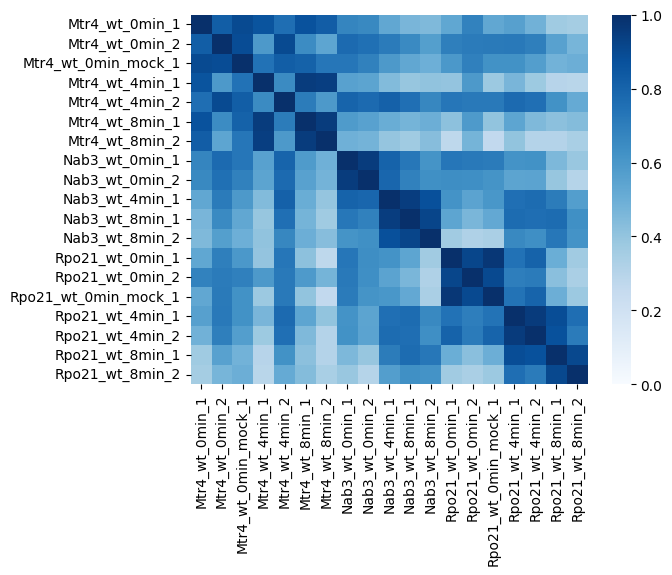

In [122]:
plotdata = df01_multi.loc[df01_multi.index.isin(top_2k_mrna['gene_id']), :]
sns.heatmap(
    plotdata.corr('pearson'),
    vmin=0, vmax=1,
    cmap='Blues',
)

Fig 1D

In [123]:
cut_genes = gtf_gene_df.loc[gtf_gene_df['biotype'] == 'CUTs', :].drop_duplicates(subset='gene_id')
sut_genes = gtf_gene_df.loc[gtf_gene_df['biotype'] == 'SUTs', :].drop_duplicates(subset='gene_id')

In [124]:
# Exclude mock samples
sample_cols = df01_multi.columns[
    ~df01_multi.columns.str.contains(r"(^|_)mock(_|$)", case=False, regex=True)
]

# Remove replicate suffix and average replicates
sample_groups = sample_cols.to_series().str.replace(
    r"_\d+$", "", regex=True
)

df01_mean = (
    df01_multi.loc[:, sample_cols]
    .T.groupby(sample_groups, sort=False)
    .mean()
    .T
)

/tmp/ipykernel_770968/3636475077.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ~df01_multi.columns.str.contains(r"(^|_)mock(_|$)", case=False, regex=True)


In [125]:
df01_mean_cuts = df01_mean.loc[df01_mean.index.isin(cut_genes['gene_id']), :].copy().add(0.1)
df01_mean_suts = df01_mean.loc[df01_mean.index.isin(sut_genes['gene_id']), :].copy().add(0.1)
df01_mean_mrnas = df01_mean.loc[df01_mean.index.isin(mrna_genes['gene_id']), :].copy().add(0.1)

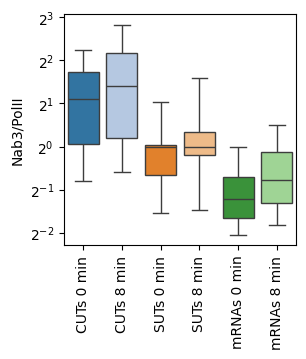

In [126]:
#Nab3/PolII
plotdata = pd.DataFrame({
    'CUTs 0 min': df01_mean_cuts['Nab3_wt_0min'].div(df01_mean_cuts['Rpo21_wt_0min']),
    'CUTs 8 min': df01_mean_cuts['Nab3_wt_8min'].div(df01_mean_cuts['Rpo21_wt_8min']),
    'SUTs 0 min': df01_mean_suts['Nab3_wt_0min'].div(df01_mean_suts['Rpo21_wt_0min']),
    'SUTs 8 min': df01_mean_suts['Nab3_wt_8min'].div(df01_mean_suts['Rpo21_wt_8min']),
    'mRNAs 0 min': df01_mean_mrnas['Nab3_wt_0min'].div(df01_mean_mrnas['Rpo21_wt_0min']),
    'mRNAs 8 min': df01_mean_mrnas['Nab3_wt_8min'].div(df01_mean_mrnas['Rpo21_wt_8min']),
})
fig, ax = plt.subplots(figsize=(3, 3))
sns.boxplot(
    data=plotdata,
    showfliers=False, whis=(10,90),
    palette='tab20',
    ax=ax
)
ax.set_yscale('log', base=2)
ax.set_ylabel('Nab3/PolII')
ax.tick_params(axis='x', labelrotation=90)

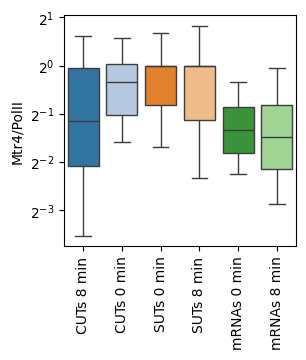

In [127]:
#Mtr4/PolII
plotdata = pd.DataFrame({
    'CUTs 8 min': df01_mean_cuts['Mtr4_wt_8min'].div(df01_mean_cuts['Rpo21_wt_8min']),
    'CUTs 0 min': df01_mean_cuts['Mtr4_wt_0min'].div(df01_mean_cuts['Rpo21_wt_0min']),
    'SUTs 0 min': df01_mean_suts['Mtr4_wt_0min'].div(df01_mean_suts['Rpo21_wt_0min']),
    'SUTs 8 min': df01_mean_suts['Mtr4_wt_8min'].div(df01_mean_suts['Rpo21_wt_8min']),
    'mRNAs 0 min': df01_mean_mrnas['Mtr4_wt_0min'].div(df01_mean_mrnas['Rpo21_wt_0min']),
    'mRNAs 8 min': df01_mean_mrnas['Mtr4_wt_8min'].div(df01_mean_mrnas['Rpo21_wt_8min']),
})
fig, ax = plt.subplots(figsize=(3, 3))
sns.boxplot(
    data=plotdata,
    showfliers=False, whis=(10,90),
    palette='tab20',
    ax=ax
)
ax.set_yscale('log', base=2)
ax.set_ylabel('Mtr4/PolII')
ax.tick_params(axis='x', labelrotation=90)